# CRISP-DM phase 2 : Data Understanding, D3 (Heart Disease Dataset (johnsmith88))

Responsable : Aziz (maladies cardiaques)

**À surveiller :** 1025 lignes mais environ 302 patients uniques : les doublons se retrouvent dans le train ET le test, ce qui gonfle les scores (98-100 % dans l'article). Point clé de la discussion critique.

In [1]:
import sys, pathlib
sys.path.insert(0, str(pathlib.Path.cwd().parents[1]))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from src.datasets import load, REGISTRY

DS = 'D3'
df, target = load(DS)   # vérifie aussi la taille face au tableau 2 de l'article
REGISTRY[DS]['name'], df.shape

[D3] lignes=1025 pos=526 neg=499 | article: lignes=1025 pos=526 neg=499 -> OK


('Heart Disease Dataset', (1025, 14))

## 1. Structure et dictionnaire des variables
Compléter le tableau dans le rapport : nom, signification médicale, type (numérique, binaire, catégorielle), unité.

In [2]:
df.head()

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,52,1,0,125,212,0,1,168,0,1.0,2,2,3,0
1,53,1,0,140,203,1,0,155,1,3.1,0,0,3,0
2,70,1,0,145,174,0,1,125,1,2.6,0,0,3,0
3,61,1,0,148,203,0,1,161,0,0.0,2,1,3,0
4,62,0,0,138,294,1,1,106,0,1.9,1,3,2,0


In [3]:
pd.DataFrame({'dtype': df.dtypes, 'n_unique': df.nunique(), 'min': df.min(numeric_only=True), 'max': df.max(numeric_only=True)})

,dtype,n_unique,min,max
age,int64,41,29.0,77.0
sex,int64,2,0.0,1.0
cp,int64,4,0.0,3.0
trestbps,int64,49,94.0,200.0
chol,int64,152,126.0,564.0
fbs,int64,2,0.0,1.0
restecg,int64,3,0.0,2.0
thalach,int64,91,71.0,202.0
exang,int64,2,0.0,1.0
oldpeak,float64,40,0.0,6.2


## 2. Variable cible

target
0    499
1    526
Name: count, dtype: int64 
 target
0    0.487
1    0.513
Name: count, dtype: float64


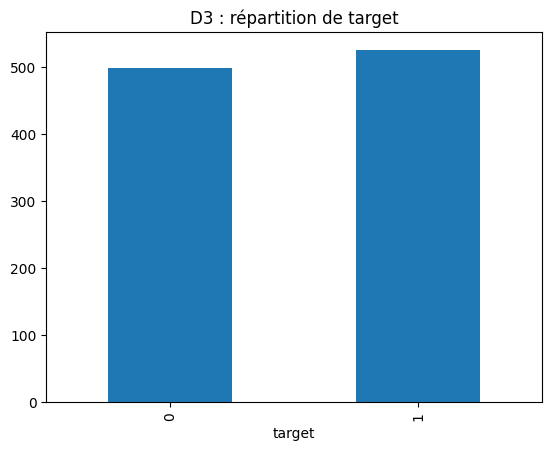

In [4]:
counts = df[target].value_counts().sort_index()
print(counts, '\n', (counts / len(df)).round(3))
counts.plot.bar(title=f'{DS} : répartition de {target}'); plt.show()

## 3. Valeurs manquantes (vraies et codées)

In [5]:
print(df.isna().sum()[df.isna().sum() > 0])
# zéros médicalement impossibles
for c in ['cholesterol', 'chol', 'resting bp s', 'trestbps', 'serum_sodium', 'platelets']:
    if c in df: print(c, '= 0 :', (df[c] == 0).sum())
for c, code in [('ca', 4), ('thal', 0)]:
    if c in df: print(c, '=', code, ':', (df[c] == code).sum())

Series([], dtype: int64)
chol = 0 : 0
trestbps = 0 : 0
ca = 4 : 18
thal = 0 : 7


## 4. Doublons
L'article ne dit pas les avoir supprimés : on les **garde** pour reproduire ses résultats, puis on relance avec `--dedup` pour mesurer leur effet.

In [6]:
n_dup = df.duplicated().sum()
print(f'{n_dup} doublons sur {len(df)} lignes -> {len(df) - n_dup} lignes uniques')
df.drop_duplicates()[target].value_counts()

723 doublons sur 1025 lignes -> 302 lignes uniques


target
1    164
0    138
Name: count, dtype: int64

## 5. Statistiques descriptives et distributions

In [7]:
df.describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
age,1025.0,54.43,9.07,29.0,48.0,56.0,61.0,77.0
sex,1025.0,0.70,0.46,0.0,0.0,1.0,1.0,1.0
cp,1025.0,0.94,1.03,0.0,0.0,1.0,2.0,3.0
trestbps,1025.0,131.61,17.52,94.0,120.0,130.0,140.0,200.0
chol,1025.0,246.00,51.59,126.0,211.0,240.0,275.0,564.0
fbs,1025.0,0.15,0.36,0.0,0.0,0.0,0.0,1.0
restecg,1025.0,0.53,0.53,0.0,0.0,1.0,1.0,2.0
thalach,1025.0,149.11,23.01,71.0,132.0,152.0,166.0,202.0
exang,1025.0,0.34,0.47,0.0,0.0,0.0,1.0,1.0
oldpeak,1025.0,1.07,1.18,0.0,0.0,0.8,1.8,6.2


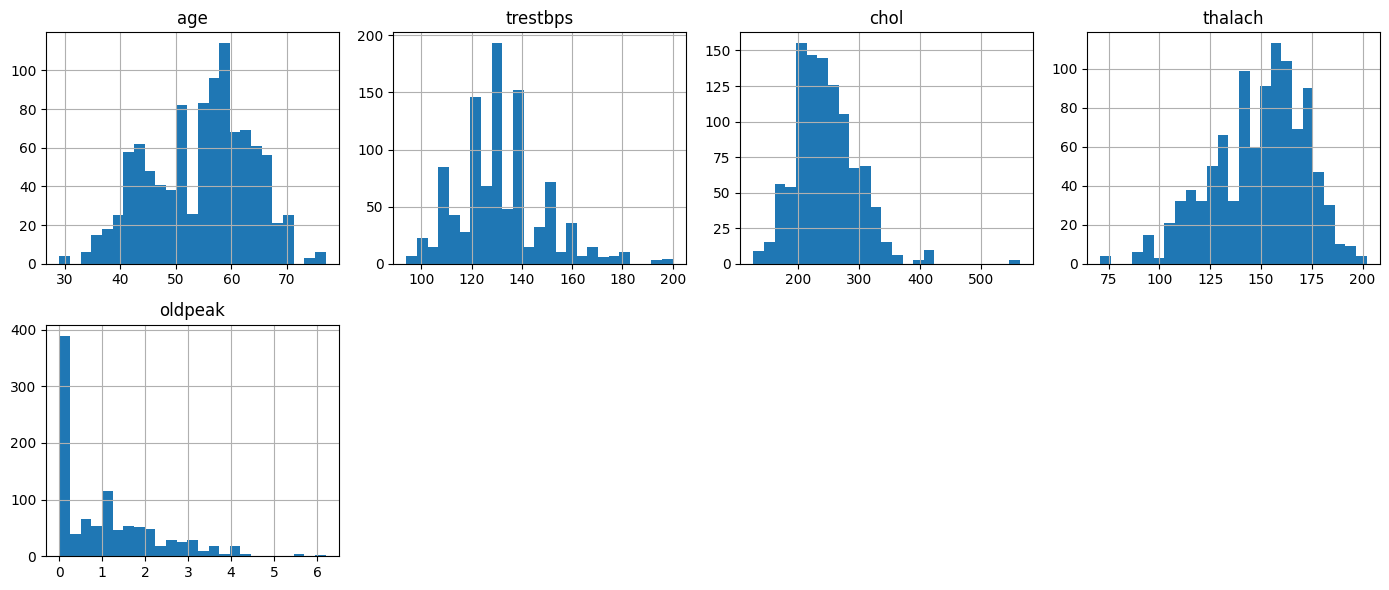

In [8]:
num = [c for c in df.columns if c != target and df[c].nunique() > 5]
df[num].hist(bins=25, figsize=(14, 3 * ((len(num) + 3) // 4)), layout=(-1, 4)); plt.tight_layout(); plt.show()

## 6. Valeurs aberrantes (méthode IQR)
Interpréter médicalement : erreur de saisie ou patient réellement extrême ?

In [9]:
q1, q3 = df[num].quantile(0.25), df[num].quantile(0.75)
iqr = q3 - q1
((df[num] < q1 - 1.5 * iqr) | (df[num] > q3 + 1.5 * iqr)).sum().sort_values(ascending=False)

trestbps    30
chol        16
oldpeak      7
thalach      4
age          0
dtype: int64

## 7. Variables selon la classe

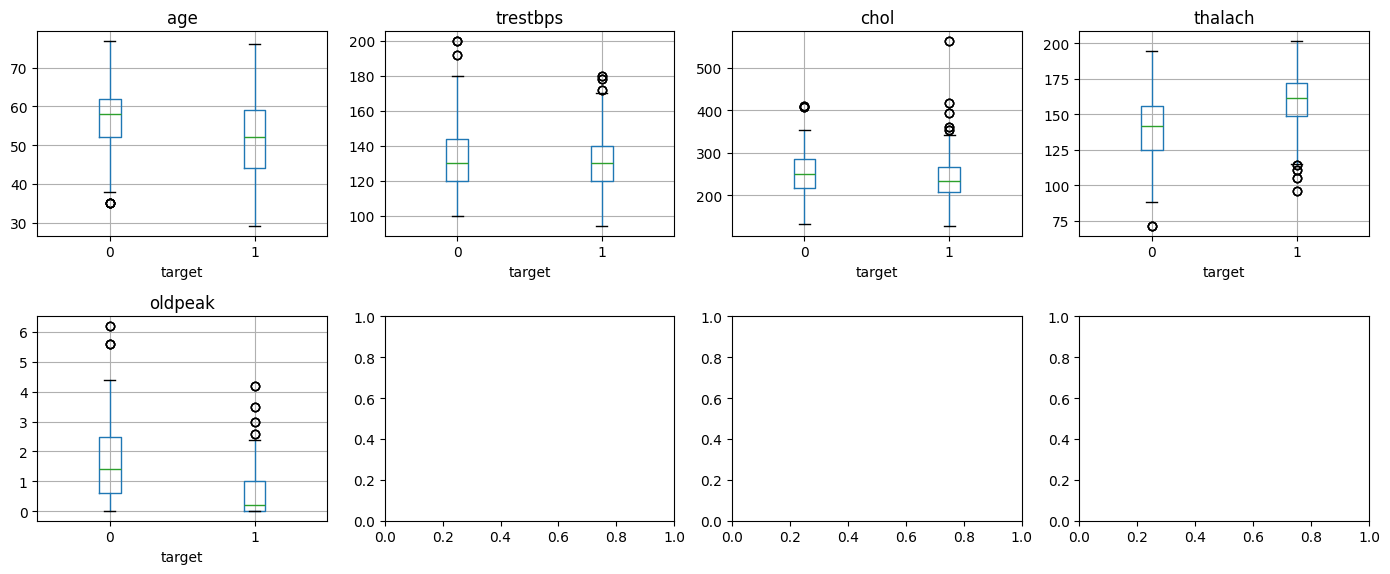

In [10]:
fig, axes = plt.subplots((len(num) + 3) // 4, 4, figsize=(14, 3 * ((len(num) + 3) // 4)))
for ax, c in zip(axes.flat, num):
    df.boxplot(column=c, by=target, ax=ax)
plt.suptitle(''); plt.tight_layout(); plt.show()

In [11]:
cat = [c for c in df.columns if c != target and df[c].nunique() <= 5]
for c in cat:
    print(pd.crosstab(df[c], df[target], normalize='index').round(2), '\n')

target     0     1
sex               
0       0.28  0.72
1       0.58  0.42 

target     0     1
cp                
0       0.75  0.25
1       0.20  0.80
2       0.23  0.77
3       0.34  0.66 

target     0     1
fbs               
0       0.48  0.52
1       0.54  0.46 

target      0     1
restecg            
0        0.57  0.43
1        0.40  0.60
2        0.80  0.20 



target     0     1
exang             
0       0.33  0.67
1       0.79  0.21 

target     0     1
slope             
0       0.62  0.38
1       0.67  0.33
2       0.28  0.72 

target     0     1
ca                
0       0.28  0.72
1       0.71  0.29
2       0.84  0.16
3       0.87  0.13
4       0.17  0.83 

target     0     1
thal              
0       0.57  0.43
1       0.67  0.33
2       0.24  0.76
3       0.78  0.22 



## 8. Corrélations

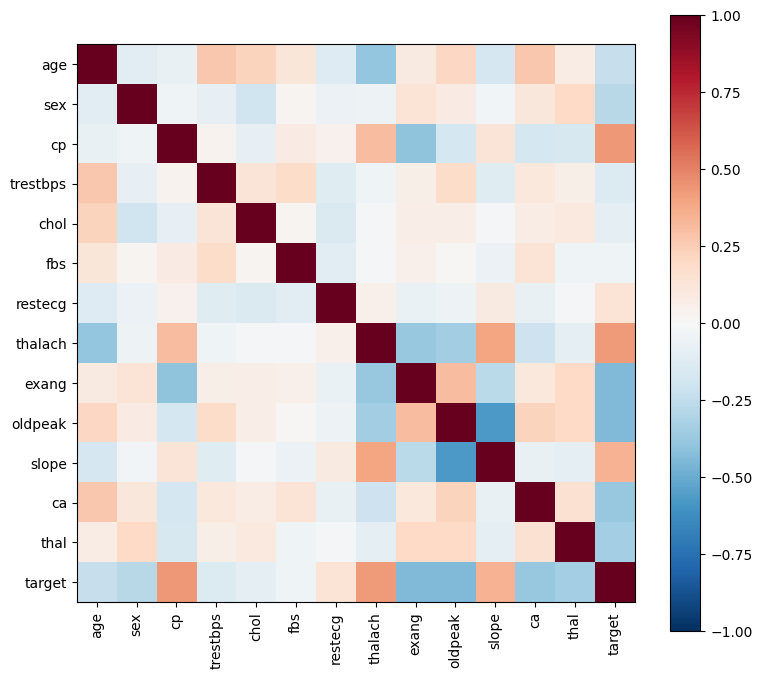

oldpeak    -0.438441
exang      -0.438029
cp          0.434854
thalach     0.422895
ca         -0.382085
slope       0.345512
thal       -0.337838
sex        -0.279501
age        -0.229324
trestbps   -0.138772
restecg     0.134468
chol       -0.099966
fbs        -0.041164
Name: target, dtype: float64

In [12]:
corr = df.select_dtypes('number').corr()
fig, ax = plt.subplots(figsize=(9, 8))
im = ax.imshow(corr, cmap='RdBu_r', vmin=-1, vmax=1)
ax.set_xticks(range(len(corr)), corr.columns, rotation=90); ax.set_yticks(range(len(corr)), corr.columns)
plt.colorbar(im); plt.show()
corr[target].drop(target).sort_values(key=abs, ascending=False)

## 9. Conclusions pour la préparation (phase 3)

- Variables à encoder :
- Valeurs manquantes / codées à traiter :
- Doublons : gardés (reproduction) + expérience `--dedup`
- Normalisation : StandardScaler dans le Pipeline (ajusté sur le train)
- Points pour la discussion critique :